# 01 - Data Preprocessing

## Project
**Machine Learning Analysis of Life Satisfaction Among Foreign Residents in Seoul**

## Objective
Prepare a clean, reproducible, and model-ready version of the 2025 Seoul Survey foreign-resident data while preserving the original survey semantics.

This notebook follows the preprocessing concepts covered in the Machine Learning and Data Mining courses:

- data quality checking;
- attribute-type identification;
- missing-value handling;
- duplicate checking;
- discretization and binarization;
- attribute transformation;
- feature creation;
- representative train/test sampling;
- feature scaling;
- feature subset preparation;
- leakage prevention.

The raw dataset is never overwritten.


## 1. Import Libraries


In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler

pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)

RANDOM_STATE = 42
TEST_SIZE = 0.20
SURVEY_YEAR = 2025


## 2. Locate the Project and Raw Dataset

The project root is detected automatically so that the notebook works from VS Code, Jupyter, or the repository root.


In [3]:
def find_project_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()

    for candidate in [current, *current.parents]:
        if (candidate / "data").exists() and (candidate / "notebooks").exists():
            return candidate

    raise FileNotFoundError("Project root could not be located.")


PROJECT_ROOT = find_project_root()
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "seoul_survey_foreigners_2025.xlsx"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
RESULTS_DIR = PROJECT_ROOT / "results"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Dataset exists:", DATA_PATH.exists())


Project root: /Users/akarehteinlin/Desktop/seoul-foreigners-ml
Dataset exists: True


## 3. Load the Raw Survey and Codebook


In [4]:
xls = pd.ExcelFile(DATA_PATH)

data_sheet = xls.sheet_names[0]
codebook_candidates = [s for s in xls.sheet_names if "코드북" in str(s)]
codebook_sheet = codebook_candidates[0] if codebook_candidates else None

raw_df = pd.read_excel(DATA_PATH, sheet_name=data_sheet)
codebook = pd.read_excel(DATA_PATH, sheet_name=codebook_sheet) if codebook_sheet else None

print("Data sheet:", data_sheet)
print("Codebook sheet:", codebook_sheet)
print("Raw dataset shape:", raw_df.shape)


Data sheet: 2025년 서울서베이_외국인_data(260323,  구
Codebook sheet: 코드북
Raw dataset shape: (2500, 157)


## 4. Structural Validation

Before cleaning, verify the expected respondent identifier, target, and core variables.


In [5]:
required_columns = [
    "ID", "Q11", "SQ3", "SQ4_1", "SQ4_2",
    "Q1_1", "Q1_2", "Q1_3", "Q1_4"
]

missing_required = [c for c in required_columns if c not in raw_df.columns]

assert not missing_required, f"Missing required columns: {missing_required}"
assert raw_df["ID"].is_unique, "ID must uniquely identify respondents."

print("Required columns: OK")
print("Respondents:", len(raw_df))
print("Unique IDs:", raw_df["ID"].nunique())
print("Exact duplicate rows:", raw_df.duplicated().sum())


Required columns: OK
Respondents: 2500
Unique IDs: 2500
Exact duplicate rows: 0


## 5. Data Quality Audit

Data quality problems discussed in class include missing values, duplicate data, wrong values, noise, and outliers.

This notebook first detects possible problems. It does **not** automatically remove unusual observations unless there is a clear survey or domain-based reason.


In [6]:
quality_overview = pd.DataFrame({
    "dtype": raw_df.dtypes.astype(str),
    "non_missing": raw_df.notna().sum(),
    "missing": raw_df.isna().sum(),
    "missing_percent": (raw_df.isna().mean() * 100).round(2),
    "unique_values": raw_df.nunique(dropna=True),
})

quality_overview.sort_values("missing_percent", ascending=False).head(30)


,dtype,non_missing,missing,missing_percent,unique_values
Q23_2_10,float64,0,2500,100.00,0
Q29_4,float64,1,2499,99.96,1
Q17_4,float64,3,2497,99.88,1
Q13_8,float64,4,2496,99.84,1
Q17_3,float64,10,2490,99.60,2
Q21_7,float64,11,2489,99.56,1
Q13_7,float64,18,2482,99.28,2
Q21_6,float64,21,2479,99.16,3
Q29_3,float64,41,2459,98.36,3
Q13_6,float64,57,2443,97.72,3


## 6. Duplicate Data

Exact duplicate records are checked separately from duplicate respondent IDs.

If exact duplicates are found, they can be removed because they repeat the same record. Distinct records with unusual values are not treated as duplicates.


In [7]:
df = raw_df.copy()

duplicate_rows = df.duplicated().sum()
duplicate_ids = df["ID"].duplicated().sum()

print("Exact duplicate rows:", duplicate_rows)
print("Duplicate respondent IDs:", duplicate_ids)

if duplicate_rows > 0:
    df = df.drop_duplicates().copy()

print("Rows after duplicate check:", len(df))


Exact duplicate rows: 0
Duplicate respondent IDs: 0
Rows after duplicate check: 2500


## 7. Attribute Types

A numeric storage type does not imply a quantitative attribute.

Survey variables stored as integers may represent:

- **Nominal:** categories without order, such as nationality or visa type.
- **Ordinal:** ordered categories, such as language proficiency.
- **Interval:** meaningful differences but no true zero.
- **Ratio:** meaningful differences and a true zero, such as age, duration, counts, or monetary values.
- **Binary:** two-state nominal variables.

Correct attribute classification determines which preprocessing operations are meaningful.


In [8]:
attribute_type_examples = pd.DataFrame([
    {"variable":"ID", "attribute_type":"Nominal / identifier", "reason":"Identifier; numeric value has no magnitude"},
    {"variable":"SQ1", "attribute_type":"Nominal", "reason":"Nationality code"},
    {"variable":"SQ2", "attribute_type":"Nominal", "reason":"Visa/status category code"},
    {"variable":"SQ7", "attribute_type":"Nominal / binary", "reason":"Two-category demographic attribute"},
    {"variable":"Q1_1", "attribute_type":"Ordinal", "reason":"Ordered Korean proficiency scale"},
    {"variable":"Q1_2", "attribute_type":"Ordinal", "reason":"Ordered Korean proficiency scale"},
    {"variable":"Q1_3", "attribute_type":"Ordinal", "reason":"Ordered Korean proficiency scale"},
    {"variable":"Q1_4", "attribute_type":"Ordinal", "reason":"Ordered Korean proficiency scale"},
    {"variable":"Q11", "attribute_type":"Ordinal/approximately interval", "reason":"0-10 life-satisfaction rating"},
    {"variable":"age", "attribute_type":"Ratio", "reason":"Derived age has a meaningful zero and distance"},
    {"variable":"months_in_korea", "attribute_type":"Ratio", "reason":"Elapsed residence time"},
])

attribute_type_examples


,variable,attribute_type,reason
0,ID,Nominal / identifier,Identifier; numeric value has no magnitude
1,SQ1,Nominal,Nationality code
2,SQ2,Nominal,Visa/status category code
3,SQ7,Nominal / binary,Two-category demographic attribute
4,Q1_1,Ordinal,Ordered Korean proficiency scale
5,Q1_2,Ordinal,Ordered Korean proficiency scale
6,Q1_3,Ordinal,Ordered Korean proficiency scale
7,Q1_4,Ordinal,Ordered Korean proficiency scale
8,Q11,Ordinal/approximately interval,0-10 life-satisfaction rating
9,age,Ratio,Derived age has a meaningful zero and distance


## 8. Missing Values and Non-Applicable Responses

Missing values may occur because information was not collected or because a question was not applicable.

Therefore, no global `fillna(0)` operation is used.

Verified special survey codes are converted to `NaN` only when the codebook indicates that they are outside the valid measurement scale.


In [9]:
# Q6_* variables measure difficulties living in Seoul.
# Code 9 is treated as non-applicable rather than as part of the 1–5 scale.

difficulty_columns = [c for c in [f"Q6_{i}" for i in range(1, 13)] if c in df.columns]

special_code_report = []

for column in difficulty_columns:
    count_9 = int((df[column] == 9).sum())

    if count_9 > 0:
        special_code_report.append({
            "variable": column,
            "special_code": 9,
            "interpretation": "non-applicable / outside valid scale",
            "count": count_9
        })
        df[column] = df[column].replace(9, np.nan)

special_code_report = pd.DataFrame(special_code_report)
special_code_report


,variable,special_code,interpretation,count
0,Q6_2,9,non-applicable / outside valid scale,1315
1,Q6_6,9,non-applicable / outside valid scale,80
2,Q6_8,9,non-applicable / outside valid scale,405
3,Q6_10,9,non-applicable / outside valid scale,27


In [10]:
missing_after_recode = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
}).sort_values("missing_percent", ascending=False)

missing_after_recode.head(30)


,missing_count,missing_percent
Q23_2_10,2500,100.00
Q29_4,2499,99.96
Q17_4,2497,99.88
Q13_8,2496,99.84
Q17_3,2490,99.60
Q21_7,2489,99.56
Q13_7,2482,99.28
Q21_6,2479,99.16
Q29_3,2459,98.36
Q13_6,2443,97.72


## 9. Target Definition and Binarization

`Q11` is preserved for regression.

A binary classification target is also created:

- `0` = lower life satisfaction
- `1` = high life satisfaction

The threshold is fixed at `Q11 >= 8`, matching the observed median identified during data understanding. This is a form of **binarization** and creates a second supervised-learning task without modifying the original target.


In [11]:
REGRESSION_TARGET = "Q11"
CLASSIFICATION_THRESHOLD = 8
CLASSIFICATION_TARGET = "high_satisfaction"

df[CLASSIFICATION_TARGET] = (
    df[REGRESSION_TARGET] >= CLASSIFICATION_THRESHOLD
).astype("int8")

target_distribution = (
    df[CLASSIFICATION_TARGET]
    .value_counts()
    .sort_index()
    .rename_axis("class")
    .reset_index(name="count")
)

target_distribution["percent"] = (
    target_distribution["count"] / len(df) * 100
).round(2)

target_distribution


,class,count,percent
0,0,862,34.48
1,1,1638,65.52


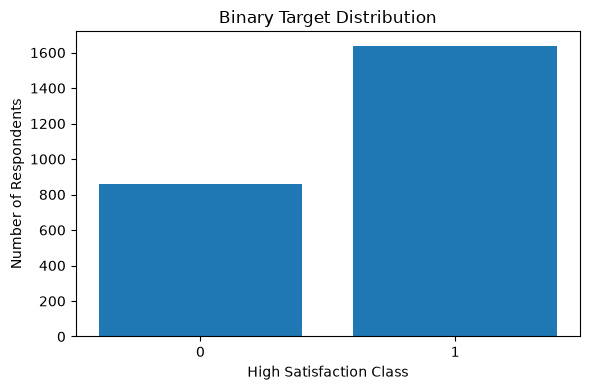

In [12]:
plt.figure(figsize=(6, 4))
plt.bar(
    target_distribution["class"].astype(str),
    target_distribution["count"]
)
plt.xlabel("High Satisfaction Class")
plt.ylabel("Number of Respondents")
plt.title("Binary Target Distribution")
plt.tight_layout()
plt.show()


## 10. Feature Creation

Feature creation combines existing information into more useful representations.

Three deterministic features are created:

1. `age`
2. `months_in_korea`
3. `korean_proficiency_mean` and its 0–10 equivalent

These transformations do not learn parameters from the dataset and therefore can be reproduced consistently.


In [13]:
df["age"] = SURVEY_YEAR - df["SQ3"]

df["months_in_korea"] = (
    df["SQ4_1"] * 12
    + df["SQ4_2"]
)

korean_skill_columns = ["Q1_1", "Q1_2", "Q1_3", "Q1_4"]

df["korean_proficiency_mean"] = (
    df[korean_skill_columns].mean(axis=1)
)

df["korean_proficiency_10"] = (
    (df["korean_proficiency_mean"] - 1) / 4 * 10
)

df[
    ["age", "months_in_korea", "korean_proficiency_mean", "korean_proficiency_10"]
].describe().T


,count,mean,std,min,25%,50%,75%,max
age,2500.0,34.27920,10.302024,20.0,26.0,33.000,40.000,84.0
months_in_korea,2500.0,58.25360,59.316944,3.0,15.0,36.000,84.000,492.0
korean_proficiency_mean,2500.0,3.59310,0.909774,1.0,3.0,3.750,4.250,5.0
korean_proficiency_10,2500.0,6.48275,2.274435,0.0,5.0,6.875,8.125,10.0


## 11. Range and Consistency Checks

Potential outliers are first identified using valid-domain rules.

An unusual value is not automatically removed. A value is removed or corrected only when it is impossible or clearly incompatible with the survey definition.


In [14]:
range_checks = pd.DataFrame([
    {
        "variable": "Q11",
        "expected_range": "0–10",
        "invalid_count": int((~df["Q11"].between(0, 10)).sum())
    },
    {
        "variable": "age",
        "expected_range": "18–100",
        "invalid_count": int((~df["age"].between(18, 100)).sum())
    },
    {
        "variable": "months_in_korea",
        "expected_range": ">= 0",
        "invalid_count": int((df["months_in_korea"] < 0).sum())
    },
    {
        "variable": "korean_proficiency_mean",
        "expected_range": "1–5",
        "invalid_count": int((~df["korean_proficiency_mean"].between(1, 5)).sum())
    },
])

range_checks


,variable,expected_range,invalid_count
0,Q11,0–10,0
1,age,18–100,0
2,months_in_korea,>= 0,0
3,korean_proficiency_mean,1–5,0


## 12. Exploratory Outlier Detection

The IQR rule is used only to flag extreme values for review.

For survey variables such as income, rent, deposit, or residence duration, extreme values may be legitimate and should not be deleted automatically.


In [15]:
outlier_candidates = [
    c for c in ["age", "months_in_korea", "SQ6_1", "SQ6_2"]
    if c in df.columns
]

iqr_outlier_report = []

for column in outlier_candidates:
    series = df[column].dropna()

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = int(((series < lower) | (series > upper)).sum())

    iqr_outlier_report.append({
        "variable": column,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_flag_boundary": lower,
        "upper_flag_boundary": upper,
        "flagged_values": count,
    })

iqr_outlier_report = pd.DataFrame(iqr_outlier_report)
iqr_outlier_report


,variable,Q1,Q3,IQR,lower_flag_boundary,upper_flag_boundary,flagged_values
0,age,26.0,40.0,14.0,5.0,61.0,40
1,months_in_korea,15.0,84.0,69.0,-88.5,187.5,96
2,SQ6_1,1000.0,5000.0,4000.0,-5000.0,11000.0,273
3,SQ6_2,45.0,65.0,20.0,15.0,95.0,44


## 13. Distribution Shape and Heavy Tails

The Machine Learning course notes that heavy-tailed positive variables may benefit from a square-root or logarithmic transformation before scaling.

Skewness is inspected here. No transformation is applied blindly.


In [16]:
continuous_review = [
    c for c in ["age", "months_in_korea", "SQ6_1", "SQ6_2"]
    if c in df.columns
]

distribution_report = pd.DataFrame({
    "variable": continuous_review,
    "skewness": [df[c].dropna().skew() for c in continuous_review],
    "min": [df[c].min() for c in continuous_review],
    "max": [df[c].max() for c in continuous_review],
})

distribution_report


,variable,skewness,min,max
0,age,0.814798,20.0,84.0
1,months_in_korea,1.999380,3.0,492.0
2,SQ6_1,5.174947,100.0,200000.0
3,SQ6_2,2.567671,10.0,250.0


## 14. Optional Log Transformation for Strongly Right-Skewed Ratio Variables

A `log1p` version is created only for non-negative ratio-scale features with strong positive skewness.

The original variable is retained so later models can compare raw and transformed representations.


In [17]:
log_transform_candidates = []

for column in continuous_review:
    non_missing = df[column].dropna()

    if (
        len(non_missing) > 0
        and non_missing.min() >= 0
        and non_missing.skew() > 1
    ):
        new_column = f"{column}_log1p"
        df[new_column] = np.log1p(df[column])
        log_transform_candidates.append({
            "source_variable": column,
            "derived_variable": new_column,
            "training_note": "Compare transformed vs. original representation"
        })

log_transform_candidates = pd.DataFrame(log_transform_candidates)
log_transform_candidates


,source_variable,derived_variable,training_note
0,months_in_korea,months_in_korea_log1p,Compare transformed vs. original representation
1,SQ6_1,SQ6_1_log1p,Compare transformed vs. original representation
2,SQ6_2,SQ6_2_log1p,Compare transformed vs. original representation


## 15. Feature Redundancy and Feature Subset Preparation

Redundant and irrelevant features can increase dimensionality without adding useful information.

This notebook documents obvious structural redundancy:

- `SQ3` vs. derived `age`
- `SQ4_1` and `SQ4_2` vs. derived `months_in_korea`
- four Korean skill variables vs. a combined proficiency score

Later modeling notebooks should choose one representation rather than automatically using all redundant forms.


In [18]:
feature_dependencies = pd.DataFrame([
    {
        "derived_feature": "age",
        "source_features": "SQ3",
        "recommended_use": "Use age instead of birth year for most models"
    },
    {
        "derived_feature": "months_in_korea",
        "source_features": "SQ4_1, SQ4_2",
        "recommended_use": "Use total months instead of separate year/month fields"
    },
    {
        "derived_feature": "korean_proficiency_10",
        "source_features": "Q1_1, Q1_2, Q1_3, Q1_4",
        "recommended_use": "Use either combined score or individual skills depending on research question"
    },
])

feature_dependencies


,derived_feature,source_features,recommended_use
0,age,SQ3,Use age instead of birth year for most models
1,months_in_korea,"SQ4_1, SQ4_2",Use total months instead of separate year/mont...
2,korean_proficiency_10,"Q1_1, Q1_2, Q1_3, Q1_4",Use either combined score or individual skills...


## 16. Leakage Audit

Identifiers and targets are excluded from predictors.

Variables conceptually very close to `Q11` are flagged as **target-proximal**. They may be useful for descriptive analysis, but including them in a predictive model can make performance look artificially strong because they measure nearly the same construct.


In [19]:
IDENTIFIER_COLUMNS = ["ID"]
TARGET_COLUMNS = ["Q11", "high_satisfaction"]

TARGET_PROXIMAL_COLUMNS = [
    *[c for c in [f"Q4_{i}" for i in range(1, 8)] if c in df.columns],
    *[c for c in [f"Q10_{i}" for i in range(1, 6)] if c in df.columns],
    *[c for c in ["Q14"] if c in df.columns],
]

leakage_audit = pd.DataFrame({
    "variable": IDENTIFIER_COLUMNS + TARGET_COLUMNS + TARGET_PROXIMAL_COLUMNS,
    "role": (
        ["identifier"] * len(IDENTIFIER_COLUMNS)
        + ["target"] * len(TARGET_COLUMNS)
        + ["target-proximal"] * len(TARGET_PROXIMAL_COLUMNS)
    )
})

leakage_audit


,variable,role
0,ID,identifier
1,Q11,target
2,high_satisfaction,target
3,Q4_1,target-proximal
4,Q4_2,target-proximal
5,Q4_3,target-proximal
6,Q4_4,target-proximal
7,Q4_5,target-proximal
8,Q4_6,target-proximal
9,Q4_7,target-proximal


## 17. Shared Feature-Type Schema

The common schema gives all later notebooks the same preprocessing conventions.

Nominal variables are one-hot encoded. Ordinal and ratio/continuous variables remain numeric and can be scaled for algorithms that depend on distance or coefficient magnitude.


In [20]:
shared_nominal_features = [
    c for c in [
        "AREA", "SQ1", "SQ2", "SQ5", "SQ6", "SQ7", "SQ8"
    ]
    if c in df.columns
]

shared_ordinal_features = [
    c for c in ["Q1_1", "Q1_2", "Q1_3", "Q1_4"]
    if c in df.columns
]

shared_continuous_features = [
    c for c in [
        "age",
        "months_in_korea",
        "SQ6_1",
        "SQ6_2",
        "korean_proficiency_10",
    ]
    if c in df.columns
]

feature_schema = pd.DataFrame(
    [
        *[
            {
                "variable": c,
                "attribute_type": "nominal",
                "preprocessing": "mode imputation + one-hot encoding"
            }
            for c in shared_nominal_features
        ],
        *[
            {
                "variable": c,
                "attribute_type": "ordinal",
                "preprocessing": "median imputation + optional scaling"
            }
            for c in shared_ordinal_features
        ],
        *[
            {
                "variable": c,
                "attribute_type": "ratio/continuous",
                "preprocessing": "median imputation + optional transformation + scaling"
            }
            for c in shared_continuous_features
        ],
    ]
)

feature_schema


,variable,attribute_type,preprocessing
0,AREA,nominal,mode imputation + one-hot encoding
1,SQ1,nominal,mode imputation + one-hot encoding
2,SQ2,nominal,mode imputation + one-hot encoding
3,SQ5,nominal,mode imputation + one-hot encoding
4,SQ6,nominal,mode imputation + one-hot encoding
5,SQ7,nominal,mode imputation + one-hot encoding
6,SQ8,nominal,mode imputation + one-hot encoding
7,Q1_1,ordinal,median imputation + optional scaling
8,Q1_2,ordinal,median imputation + optional scaling
9,Q1_3,ordinal,median imputation + optional scaling


## 18. Representative Train/Test Sampling

The class notes emphasize that a sample should preserve important properties of the original population.

A stratified 80/20 split is therefore created using the binary satisfaction target. This preserves approximately the same class proportions in train and test sets.


In [21]:
split_frame = df[["ID", CLASSIFICATION_TARGET]].copy()

train_split, test_split = train_test_split(
    split_frame,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=split_frame[CLASSIFICATION_TARGET],
)

train_ids = set(train_split["ID"])
test_ids = set(test_split["ID"])

assert train_ids.isdisjoint(test_ids)
assert len(train_ids) + len(test_ids) == len(df)

split_summary = pd.DataFrame({
    "split": ["train", "test"],
    "rows": [len(train_split), len(test_split)],
    "percent": [
        round(len(train_split) / len(df) * 100, 2),
        round(len(test_split) / len(df) * 100, 2),
    ],
    "high_satisfaction_percent": [
        round(train_split[CLASSIFICATION_TARGET].mean() * 100, 2),
        round(test_split[CLASSIFICATION_TARGET].mean() * 100, 2),
    ],
})

split_summary


,split,rows,percent,high_satisfaction_percent
0,train,2000,80.0,65.5
1,test,500,20.0,65.6


## 19. Scaling Strategy

Two scaling methods covered in class are supported:

- **Standardization:** mean 0 and standard deviation 1.
- **Min-max normalization:** values mapped to the 0–1 range.

Standardization is the default for Logistic Regression and SVM experiments. Min-max scaling remains available for experiments where bounded inputs are preferred.

All scalers are fitted on **training data only**.


In [22]:
def build_preprocessor(
    nominal_features: list[str],
    ordinal_features: list[str],
    continuous_features: list[str],
    scaler: str = "standard",
) -> ColumnTransformer:

    if scaler == "standard":
        numeric_scaler = StandardScaler()
    elif scaler == "minmax":
        numeric_scaler = MinMaxScaler()
    else:
        raise ValueError("scaler must be 'standard' or 'minmax'")

    nominal_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", numeric_scaler),
    ])

    return ColumnTransformer(
        transformers=[
            ("nominal", nominal_pipeline, nominal_features),
            ("ordinal", numeric_pipeline, ordinal_features),
            ("continuous", numeric_pipeline, continuous_features),
        ],
        remainder="drop",
        verbose_feature_names_out=True,
    )


## 20. Fit Preprocessing on Training Data Only

This is the main leakage-prevention rule of the preprocessing stage.


In [23]:
shared_features = (
    shared_nominal_features
    + shared_ordinal_features
    + shared_continuous_features
)

train_mask = df["ID"].isin(train_ids)
test_mask = df["ID"].isin(test_ids)

X_train = df.loc[train_mask, shared_features].copy()
X_test = df.loc[test_mask, shared_features].copy()

standard_preprocessor = build_preprocessor(
    shared_nominal_features,
    shared_ordinal_features,
    shared_continuous_features,
    scaler="standard",
)

X_train_prepared = standard_preprocessor.fit_transform(X_train)
X_test_prepared = standard_preprocessor.transform(X_test)

prepared_feature_names = standard_preprocessor.get_feature_names_out()

print("Raw shared features:", len(shared_features))
print("Prepared train shape:", X_train_prepared.shape)
print("Prepared test shape:", X_test_prepared.shape)
print("Prepared feature count:", len(prepared_feature_names))


Raw shared features: 16
Prepared train shape: (2000, 76)
Prepared test shape: (500, 76)
Prepared feature count: 76


## 21. Compare Standardization and Min-Max Normalization

This comparison confirms that both transformations are available without changing the train/test split.


In [24]:
minmax_preprocessor = build_preprocessor(
    shared_nominal_features,
    shared_ordinal_features,
    shared_continuous_features,
    scaler="minmax",
)

X_train_minmax = minmax_preprocessor.fit_transform(X_train)

scaling_comparison = pd.DataFrame({
    "method": ["standardization", "min-max normalization"],
    "train_rows": [X_train_prepared.shape[0], X_train_minmax.shape[0]],
    "output_features": [X_train_prepared.shape[1], X_train_minmax.shape[1]],
})

scaling_comparison


,method,train_rows,output_features
0,standardization,2000,76
1,min-max normalization,2000,76


## 22. Dimensionality Reduction Decision

The Data Mining course presents dimensionality reduction and PCA as methods for reducing high-dimensional data, computation, noise, and visualization difficulty.

PCA is **not applied in this shared preprocessing notebook** because:

1. one-hot encoding has not yet been finalized for every team-specific feature set;
2. tree-based models do not require PCA;
3. PCA reduces interpretability, while this project explicitly wants to identify important social factors;
4. dimensionality reduction should be evaluated as a model-specific experiment, not imposed on every model.

A PCA experiment can be added later to the integrated modeling notebook.


## 23. Export the Modeling Master Dataset

The master dataset contains deterministic cleaning and feature creation, but retains missing values.

Imputation, encoding, and scaling remain inside model pipelines so they can be fitted on training data only.


In [25]:
master_path = PROCESSED_DIR / "seoul_foreigners_modeling_master.csv"

df.to_csv(
    master_path,
    index=False,
    encoding="utf-8-sig"
)

print("Saved:", master_path)
print("Shape:", df.shape)


Saved: /Users/akarehteinlin/Desktop/seoul-foreigners-ml/data/processed/seoul_foreigners_modeling_master.csv
Shape: (2500, 165)


## 24. Export Shared Split and Preprocessing Metadata


In [26]:
train_split[["ID"]].to_csv(PROCESSED_DIR / "train_ids.csv", index=False)
test_split[["ID"]].to_csv(PROCESSED_DIR / "test_ids.csv", index=False)

feature_schema.to_csv(
    RESULTS_DIR / "preprocessing_feature_schema.csv",
    index=False
)

feature_dependencies.to_csv(
    RESULTS_DIR / "preprocessing_feature_dependencies.csv",
    index=False
)

leakage_audit.to_csv(
    RESULTS_DIR / "preprocessing_leakage_audit.csv",
    index=False
)

missing_after_recode.to_csv(
    RESULTS_DIR / "preprocessing_missing_values.csv"
)

iqr_outlier_report.to_csv(
    RESULTS_DIR / "preprocessing_outlier_flags.csv",
    index=False
)

distribution_report.to_csv(
    RESULTS_DIR / "preprocessing_distribution_shape.csv",
    index=False
)

target_distribution.to_csv(
    RESULTS_DIR / "preprocessing_target_distribution.csv",
    index=False
)

if not special_code_report.empty:
    special_code_report.to_csv(
        RESULTS_DIR / "preprocessing_special_codes.csv",
        index=False
    )

if not log_transform_candidates.empty:
    log_transform_candidates.to_csv(
        RESULTS_DIR / "preprocessing_log_transform_candidates.csv",
        index=False
    )

print("Preprocessing metadata exported successfully.")


Preprocessing metadata exported successfully.


## 25. Final Validation


In [27]:
final_checks = {
    "raw_rows": len(raw_df),
    "processed_rows": len(df),
    "processed_columns": df.shape[1],
    "unique_ids": df["ID"].nunique(),
    "train_rows": len(train_ids),
    "test_rows": len(test_ids),
    "q11_missing": int(df["Q11"].isna().sum()),
    "classification_target_missing": int(df["high_satisfaction"].isna().sum()),
    "shared_raw_features": len(shared_features),
    "prepared_features": len(prepared_feature_names),
}

pd.Series(final_checks, name="value").to_frame()


,value
raw_rows,2500
processed_rows,2500
processed_columns,165
unique_ids,2500
train_rows,2000
test_rows,500
q11_missing,0
classification_target_missing,0
shared_raw_features,16
prepared_features,76


In [28]:
assert len(df) == len(raw_df)
assert df["ID"].is_unique
assert df["Q11"].notna().all()
assert df["high_satisfaction"].notna().all()
assert train_ids.isdisjoint(test_ids)
assert len(train_ids) + len(test_ids) == len(df)

for forbidden in IDENTIFIER_COLUMNS + TARGET_COLUMNS:
    assert forbidden not in shared_features

print("Preprocessing notebook completed successfully.")
print(f"Respondents: {len(df):,}")
print(f"Train respondents: {len(train_ids):,}")
print(f"Test respondents: {len(test_ids):,}")
print(f"Classification target: Q11 >= {CLASSIFICATION_THRESHOLD}")
print(f"Modeling master: {master_path.name}")


Preprocessing notebook completed successfully.
Respondents: 2,500
Train respondents: 2,000
Test respondents: 500
Classification target: Q11 >= 8
Modeling master: seoul_foreigners_modeling_master.csv


## Preprocessing Summary

The preprocessing stage created a shared foundation for all later analyses.

- Survey variables were interpreted according to their attribute type rather than their storage dtype.
- Missing and non-applicable values were handled conservatively.
- Exact duplicates and possible outliers were checked explicitly.
- `Q11` was retained for regression and binarized for classification.
- New ratio-scale features were constructed from birth year, residence duration, and Korean-language items.
- Heavy-tailed positive variables were identified for optional transformation instead of being transformed blindly.
- Redundant representations and target-proximal variables were documented.
- A representative stratified train/test split was created once for the entire team.
- Standardization and min-max normalization were implemented as reusable alternatives.
- Imputation, encoding, and scaling are fitted on training data only.
- PCA and final feature selection were deliberately deferred to model-specific experiments to preserve interpretability and avoid premature information loss.
